# Use-case: klantverloop (churn) voorspellen met één beslisboom

**ML Principles – use-case** · Kemal Yilmaz · AP Hogeschool, IT & AI

Dit notebook bespreekt een **bestaande analyse** van een **bestaande dataset**. Het toont waar de basisconcepten uit de cursus in die analyse terugkomen, en welke keuzes en beperkingen erbij horen.

| | Bron |
|---|---|
| Hoofdbron (analyse) | B. Borbekov, *Telco Churn Prediction – Tree Methods Compared*, Kaggle, versie 1 – enkel het onderdeel **Decision Tree** en de gedeelde stappen ervoor. <https://www.kaggle.com/code/bekzhanborbekov/telco-churn-prediction-tree-methods-compared> |
| Aanvullende bron (dataonderzoek) | B. Borbekov, *Telco Churn Prediction – 5 Models Compared*, Kaggle – enkel de exploratieve analyse. <https://www.kaggle.com/code/bekzhanborbekov/telco-churn-prediction-5-models-compared> |
| Dataset | *Telco Customer Churn* (IBM Sample Data Sets), Kaggle-gebruiker blastchar. <https://www.kaggle.com/datasets/blastchar/telco-customer-churn> |

De vergelijking met andere modellen (bagging, random forest, boosting, logistische regressie, …) uit de bronnen valt bewust buiten dit notebook.

**Wie zegt wat?** Doorheen het notebook maak ik dat onderscheid expliciet:

- 📎 **Kaggle-auteur** – code, keuzes, cijfers of conclusies die zo in de bron staan.
- 🔎 **Eigen bespreking** – mijn uitleg, koppeling met de cursus en kritische kanttekeningen.

**Wat wordt hier uitgevoerd?** De codecellen halen de dataset op en herhalen de exploratieve stappen van de auteur, zodat je de data zelf ziet. Het model wordt **niet** opnieuw getraind. De code van de auteur voor preprocessing, training en evaluatie staat als citaat in dit notebook, samen met de resultaten die hij rapporteert.

## 1. Vraag- en probleemstelling

**Churn** is klantverloop: een klant zegt zijn abonnement op en vertrekt naar een concurrent of stopt. In deze dataset betekent `Churn = Yes` dat de klant *in de laatste maand* vertrokken is (datasetbeschrijving op Kaggle).

**Welke beslissing ondersteunt het model?** Een telecombedrijf wil klanten met een hoog vertrekrisico *op tijd* herkennen, zodat het retentiemiddelen gericht kan inzetten: een telefoontje, een korting of een voorstel voor een langer contract. Het model beslist niets zelf. Het levert een **lijst van risicoklanten**, en het bedrijf beslist wie er een actie krijgt.

**Probleemdefinitie in ML-termen** (cf. *ML flow* in de cursus):

- **Taak – binaire classificatie.** Per klant voorspellen we één van twee discrete labels: *vertrekt* (1) of *blijft* (0).
- **Ervaring – supervised learning.** De historische kolom `Churn` levert de **ground truth / targetwaarden**. Het model leert de koppeling tussen klantkenmerken en een label dat vooraf vastligt.
- **Data – gestructureerd.** Eén rij per klant, vaste kolommen met heterogene datatypes (numeriek en categorisch).
- **Target:** `Churn`, de **positieve klasse** is *churn* (1). Precision, recall en F1 verderop gaan dus altijd over het herkennen van vertrekkers.

## 2. Dataset: bron, omschrijving en exploratieve analyse

### 2.1 Data ophalen

📎 De auteur leest het bestand in vanuit de Kaggle-omgeving (`/kaggle/input/...`). Dat pad bestaat buiten Kaggle niet. Daarom haalt dit notebook dezelfde dataset op met `kagglehub`, zoals in de labo's. Er is geen lokale kopie of Kaggle-account nodig: het is een publieke dataset. Ik pin **versie 1** van de dataset vast, zodat het notebook altijd exact hetzelfde bestand gebruikt. Op 22 november 2026 was dat de nieuwste en enige versie. De auteur vermeldt geen versie, maar zijn verkennende cijfers komen exact overeen met deze data (§2.3).

Alle packages (`kagglehub`, `pandas`, `matplotlib`) zitten al in de cursusomgeving. Er is dus geen extra `uv add` nodig.

In [1]:
import os

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
path = kagglehub.dataset_download("blastchar/telco-customer-churn/versions/1")
telco_raw = pd.read_csv(os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv"))

# Controle: is dit exact de verwachte dataset?
expected_columns = [
    "customerID", "gender", "SeniorCitizen", "Partner", "Dependents", "tenure",
    "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod", "MonthlyCharges", "TotalCharges", "Churn",
]  # fmt: skip
assert list(telco_raw.columns) == expected_columns, "Onverwachte kolommen"
assert telco_raw.shape == (7043, 21), f"Onverwachte vorm: {telco_raw.shape}"
assert set(telco_raw["Churn"].unique()) == {"Yes", "No"}, "Onverwachte targetwaarden"
assert telco_raw["customerID"].is_unique

print("Vorm:", telco_raw.shape)
telco_raw.head()

  0%|          | 0.00/172k [00:00<?, ?B/s]

100%|██████████| 172k/172k [00:00<00:00, 715kB/s]

100%|██████████| 172k/172k [00:00<00:00, 713kB/s]

Extracting files...


Vorm: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 2.2 Omschrijving

Elke rij is één klant (7043 klanten, 21 kolommen). De kolommen vallen in vier groepen (datasetbeschrijving op Kaggle):

| Groep | Kolommen | Meetniveau |
|---|---|---|
| Identificatie | `customerID` | geen feature |
| Demografie | `gender`, `SeniorCitizen`, `Partner`, `Dependents` | nominaal (binair) |
| Klantrelatie | `tenure` (aantal maanden klant), `MonthlyCharges`, `TotalCharges` | ratio |
| | `Contract` (maand-tot-maand / 1 jaar / 2 jaar) | ordinaal |
| | `PaperlessBilling`, `PaymentMethod` | nominaal |
| Diensten | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | nominaal |
| **Target** | `Churn` (Yes/No) | nominaal (binair) |

### 2.3 Exploratieve analyse (📎 stappen van de auteur)

📎 De auteur onderzoekt in de aanvullende bron drie dingen: de verdeling van de target, ontbrekende waarden, en welke kenmerken samenhangen met churn. De cellen hieronder herhalen die stappen in compacte vorm, zodat je de data zelf ziet. De cijfers komen overeen met wat de auteur rapporteert, op één detail na: de mediaan van `TotalCharges` wijkt licht af, omdat ik de 11 lege waarden hier nog niet als 0 meetel.

In [3]:
telco = telco_raw.set_index("customerID")

# (a) Verdeling van de target
target_verdeling = pd.DataFrame({
    "aantal": telco["Churn"].value_counts(),
    "aandeel": telco["Churn"].value_counts(normalize=True).round(3),
})  # fmt: skip
target_verdeling

,aantal,aandeel
Churn,,
No,5174,0.735
Yes,1869,0.265


**Ongebalanceerdheid.** Slechts 26,5 % van de klanten vertrekt. Een "model" dat altijd *blijft* voorspelt, haalt dus al ≈ 73,5 % accuracy zonder iets te leren. 📎 De auteur besluit daarom om accuracy niet als hoofdmaat te gebruiken, maar precision, recall en F1. Die keuze komt terug bij de split (`stratify`), de tuning (`scoring="f1"`) en de evaluatie.

In [4]:
# (b) Ontbrekende waarden: TotalCharges staat als tekst opgeslagen
print("dtype TotalCharges:", telco["TotalCharges"].dtype)
total_numeric = pd.to_numeric(telco["TotalCharges"], errors="coerce")
niet_numeriek = total_numeric.isna()
print("Niet-numerieke TotalCharges:", niet_numeriek.sum())
print("tenure van die klanten:", telco.loc[niet_numeriek, "tenure"].unique())

dtype TotalCharges: object
Niet-numerieke TotalCharges: 11
tenure van die klanten: [0]


**Missing data.** 📎 Volgens `info()` in de bron ontbreken er geen waarden, maar `TotalCharges` blijkt tekst te zijn: 11 klanten hebben er een lege string. Alle 11 hebben `tenure = 0`. Het zijn dus nieuwe klanten die nog geen factuur kregen. 📎 De auteur vult ze daarom met 0 in plaats van de rijen te verwijderen. 🔎 Dat is inhoudelijk verdedigbaar: hun opgebouwde kosten *zijn* nul.

Churnratio per contracttype:
Contract
Month-to-month    0.427
One year          0.113
Two year          0.028 

Mediaan per groep:
       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       38.0          64.425       1683.60
Yes      10.0          79.650        703.55 

Correlatie tenure–TotalCharges: 0.826


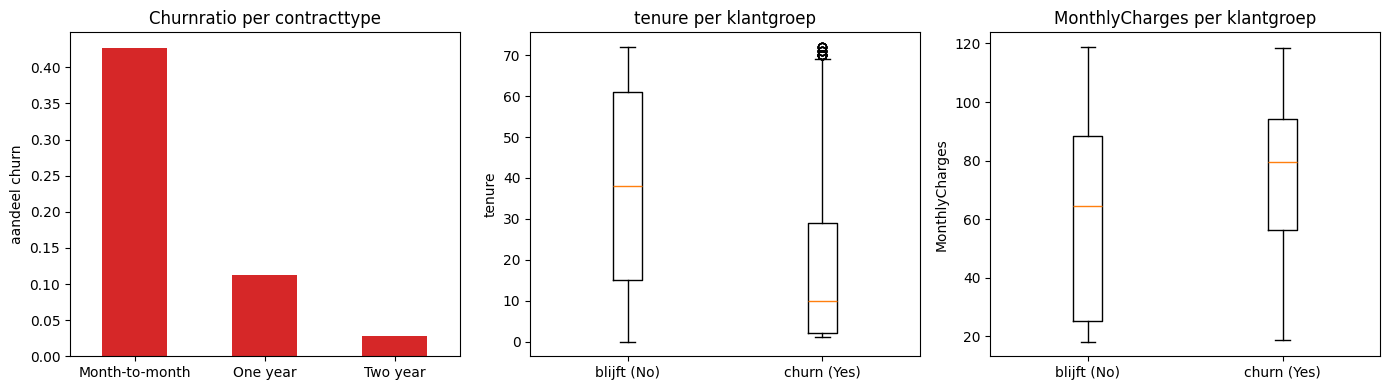

In [5]:
# (c) Samenhang van enkele kernfeatures met churn
is_churn = telco["Churn"].eq("Yes")
churn_per_contract = is_churn.groupby(telco["Contract"]).mean()
print("Churnratio per contracttype:")
print(churn_per_contract.round(3).to_string(), "\n")

numeriek = telco.assign(TotalCharges=total_numeric)[["tenure", "MonthlyCharges", "TotalCharges"]]
print("Mediaan per groep:")
print(numeriek.groupby(telco["Churn"]).median().to_string(), "\n")
print("Correlatie tenure–TotalCharges:", round(numeriek["tenure"].corr(numeriek["TotalCharges"]), 3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
churn_per_contract.plot.bar(ax=axes[0], color="tab:red", rot=0)
axes[0].set(title="Churnratio per contracttype", xlabel="", ylabel="aandeel churn")
for ax, kolom in zip(axes[1:], ["tenure", "MonthlyCharges"]):
    groepen = [numeriek.loc[~is_churn, kolom], numeriek.loc[is_churn, kolom]]
    ax.boxplot(groepen, tick_labels=["blijft (No)", "churn (Yes)"])
    ax.set(title=f"{kolom} per klantgroep", ylabel=kolom)
plt.tight_layout()
plt.show()

**Wat zegt de exploratie over de vraag?**

- **Contracttype** hangt sterk samen met churn: ≈ 43 % bij maand-tot-maand, ≈ 11 % bij 1 jaar en ≈ 3 % bij 2 jaar. 📎 De auteur noemt contract een van de sterkste voorspellers in de dataset.
- **Klantduur (`tenure`)**: vertrekkers zijn vooral nieuwe klanten (mediaan 10 maanden tegenover 38).
- **Maandelijkse kosten**: vertrekkers betalen meer per maand (mediaan ≈ 80 tegenover ≈ 64). 📎 Volgens de auteur overlappen de verdelingen sterk, dus het signaal is zwakker dan bij `tenure`.
- **`TotalCharges`** is ongeveer `tenure × MonthlyCharges` en correleert sterk met `tenure` (r ≈ 0,83). 📎 De auteur besluit dat die feature grotendeels dezelfde informatie bevat.

🔎 Dit zijn **verbanden, geen oorzaken**: dat maand-tot-maandklanten vaker vertrekken, bewijst niet dat een langer contract opdringen het vertrek voorkomt.

## 3. Modeltype: waarom een beslisboom?

📎 De auteur gebruikt een **`DecisionTreeClassifier`** uit scikit-learn: één beslisboom voor classificatie.

**Hoe werkt het model?** Een beslisboom is een boomstructuur waarbij elke vertakking een feature opsplitst, bijvoorbeeld `tenure <= 12`. Een nieuwe klant volgt de vragen van boven naar beneden tot in een **blad**. De voorspelling is de klasse die in dat blad het vaakst voorkwam bij de trainingsklanten.

- **Modelparameters** zijn hier de geleerde splitsingen (welke feature, welke drempel) en de klassenverhoudingen in de bladeren. Hoeveel parameters er komen, ligt niet vooraf vast: de **modelcomplexiteit** groeit met de boom mee.
- **Leeralgoritme:** CART zoekt *greedy* bij elke knoop de split die de knoop het **zuiverst** maakt, volgens een impurity-criterium.

**Welk splitsingscriterium?** 📎 De auteur roept `DTC(random_state=1)` aan zonder `criterion` en noemt het criterium nergens in de tekst. Hij vermeldt ook niet welke scikit-learn-versie hij gebruikte. 🔎 Volgens de scikit-learn-documentatie is de standaardwaarde `criterion="gini"`, dus vermoedelijk gebruikt de boom **Gini-impurity**. Dat is een afleiding uit de code en de documentatie, niet iets wat de bron zelf rapporteert. Hoe Gini werkt, staat uitgewerkt in mijn Mathematical Foundations-tutorial.

**Waarom past dit paradigma bij de vraag?** (🔎 eigen argumentatie op basis van de cursus)

1. Het is een supervised classificatietaak op **gestructureerde, heterogene data**. Daarvoor zijn boommodellen in de cursus het standaardvertrekpunt.
2. **Geen schaling nodig.** Een boom vergelijkt alleen drempels. 📎 De auteur laat daarom bewust `StandardScaler` weg, omdat bomen ongevoelig zijn voor monotone herschaling.
3. **Interpreteerbaarheid (explainability).** De regels van een boom zijn in principe leesbaar voor een retentieteam, bijvoorbeeld "maand-tot-maandcontract én korter dan een jaar klant".
4. **Drempeleffecten.** Een boom kan een niet-lineair verband zoals "vooral de eerste maanden zijn riskant" rechtstreeks opvangen.

**Beperkingen** (cursus): greedy optimalisatie geeft geen globaal optimale boom, kleine wijzigingen in de data kunnen een andere boom geven (instabiliteit), en een ongeremde boom kan sterk **overfitten**. Dat laatste is precies waarom de auteur snoeit (sectie 5).

## 4. Modeldefinitie: features, feature engineering en hyperparameters

### 4.1 Feature engineering (📎 code van de auteur)

```python
Telco = Telco.set_index("customerID")
Telco["TotalCharges"] = pd.to_numeric(Telco["TotalCharges"], errors="coerce").fillna(0)

cat_cols = Telco.select_dtypes(include="object").columns.drop("Churn")
Telco_encoded = pd.get_dummies(Telco, columns=cat_cols, drop_first=True)
Telco_encoded["Churn"] = Telco_encoded["Churn"].map({"Yes": 1, "No": 0})

X = Telco_encoded.drop(columns="Churn")
y = Telco_encoded["Churn"]
```

Wat er gebeurt:

1. `customerID` wordt de index en dus **geen feature**. 🔎 Een unieke ID bevat geen patroon en zou alleen tot "van buiten leren" leiden.
2. `TotalCharges` wordt numeriek gemaakt; de 11 lege waarden worden 0 (zie 2.3).
3. Alle 15 categorische kolommen krijgen **one-hot encoding** met `drop_first=True`, zodat een boom erop kan splitsen. 📎 Volgens `info()` in de bron levert dat **30 features** op.
4. De target wordt numeriek: `Yes → 1`, `No → 0`.
5. **Geen schaling** (zie sectie 3).

🔎 **Kanttekeningen bij de feature engineering**

- **Encoding vóór de split.** `get_dummies` gebruikt het churnlabel niet, en de opvulling met 0 hangt niet af van andere rijen. Toch bepaalt `get_dummies` de beschikbare categorieën op de *volledige* dataset, vóór de train/test-split. Zo heeft de testset in principe mee bepaald welke kolommen er bestaan. Voor een striktere evaluatie fit je de encoder alleen op de trainingsdata (bv. `OneHotEncoder` in een `Pipeline`) en pas je dezelfde transformatie toe op de testdata. Hier bespreek ik de methode van de auteur zoals ze in de bron staat. Dit is een kanttekening, geen aanpassing.
- **`Contract` is ordinaal**, maar wordt als twee dummies gecodeerd. De volgorde maand < 1 jaar < 2 jaar gaat zo verloren. Voor een boom is dat geen groot probleem: met twee splitsingen vindt hij dezelfde groepen terug.
- **Redundante features.** 📎 Volgens de kruistabel in de bron hebben de dienstkolommen dezelfde groep van 1526 klanten zonder internet. De dummies `..._No internet service` zijn dus identiek, en `TotalCharges` overlapt sterk met `tenure`. Voor de voorspelling is dat weinig erg, maar het maakt de interpretatie lastiger: de boom kiest één van de gelijkaardige kolommen en de andere lijkt dan onbelangrijk.

### 4.2 Hyperparameters

| Hyperparameter | Waarde in de case | Betekenis |
|---|---|---|
| `criterion` | niet opgegeven, dus de standaardwaarde van scikit-learn (`"gini"`, zie §3) | maat voor de zuiverheid van een knoop |
| `max_depth` | niet opgegeven (standaard `None`) | geen vooraf ingestelde maximale diepte |
| `min_samples_leaf` | niet opgegeven (standaard 1) | een blad moet minstens één observatie bevatten |
| `ccp_alpha` | **getuned** via cross-validatie | sterkte van het snoeien achteraf (*cost-complexity pruning*) |
| `random_state` | 1 | maakt de keuze bij gelijke splits reproduceerbaar |

🔎 Het verschil tussen **parameters** (de splitsingen, geleerd uit de data) en **hyperparameters** (instellingen van het leeralgoritme, door ons gekozen of getuned) is hier mooi zichtbaar: `ccp_alpha` bepaalt *hoeveel* splitsingen er overblijven, de data bepalen *welke*.

## 5. Modeltraining en hyperparameter tuning

### 5.1 Train/test-split (📎 code van de auteur)

```python
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
```

📎 De auteur houdt 20 % van de klanten opzij als **testdata** en gebruikt `stratify=y`, zodat de verhouding 73,5 % / 26,5 % in beide delen gelijk blijft. In de aanvullende bron levert dezelfde split 5634 trainings- en 1409 testklanten op. 🔎 Bij een ongebalanceerde target is stratificatie belangrijk: anders kan de kleine churnklasse toevallig onder- of oververtegenwoordigd zijn in de testset.

### 5.2 Tuning van `ccp_alpha` met cross-validatie (📎 code van de auteur)

```python
ccp_path = DTC(random_state=1).cost_complexity_pruning_path(X_train, y_train)
param_grid = {"ccp_alpha": ccp_path.ccp_alphas}
k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
grid = GridSearchCV(
    DTC(random_state=1),
    param_grid=param_grid,
    cv=k_fold,
    refit=True,
    scoring="f1"
).fit(X_train, y_train)
```

`DTC` is de afkorting die de auteur gebruikt voor `DecisionTreeClassifier`. De aanpak:

1. Laat eerst een **volledige boom** groeien op de trainingsdata.
2. `cost_complexity_pruning_path` berekent voor die boom alle waarden van `ccp_alpha` waarbij er een tak wegvalt. Elke waarde hoort bij een kleinere, geneste deelboom. 🔎 Die kandidaten worden vóór de cross-validatie afgeleid uit de *volledige* trainingsset. De keuze van het rooster gebruikt dus ook rijen die later als validatiefold dienen. De testset blijft wel volledig buiten die selectie.
3. `GridSearchCV` test al die kandidaten met **5-fold gestratificeerde cross-validatie** en kiest de waarde met de hoogste **F1**, niet de hoogste accuracy. 📎 Accuracy zou volgens de auteur bomen bevoordelen die te weinig churn voorspellen.

**📎 Gerapporteerd resultaat:** beste `ccp_alpha` ≈ 0,000726, met een gemiddelde CV-F1 van **0,570**. De gesnoeide boom heeft **34 bladeren**.

**🔎 Koppeling met de cursus.**

- **Training / validatie / test.** De testset blijft volledig buiten de tuning. De rol van **validatiedata** wordt gespeeld door K-fold cross-validatie *binnen* de trainingsset: elke kandidaat wordt 5 keer getraind op 4/5 van de trainingsdata en gescoord op het resterende vijfde. `refit=True` traint daarna de beste kandidaat opnieuw op de volledige trainingsset.
- **Hyperparameter tuning.** `ccp_alpha` is de enige hyperparameter die getuned wordt. De kandidaten komen uit de boom zelf, niet uit een willekeurig gekozen rooster.
- **Overfitting en generalisatie.** Zonder `max_depth` en met `min_samples_leaf=1` blijft de boom splitsen tot een knoop zuiver is of er geen geldige splitsing meer mogelijk is. Dat laatste gebeurt bijvoorbeeld bij klanten met identieke features maar een ander label, en dan blijft het blad onzuiver. Zo'n boom leert ook toevallige uitzonderingen. Snoeien ruilt een beetje fit op de trainingsdata in voor een eenvoudigere boom die beter *kan* generaliseren. Cross-validatie bepaalt hoeveel je best snoeit: te weinig geeft overfitting, te veel geeft een boom die te eenvoudig is (underfitting).

**🔎 Beperking.** De auteur toont alleen het gesnoeide resultaat. Hoe groot de ongesnoeide boom was en hoe die scoorde, staat niet in de bron. Of en hoeveel het snoeien de prestaties in deze case verbetert, kan je dus niet kwantificeren; zie de mogelijke aanvullingen in §6.3.

## 6. Performantieanalyse

### 6.1 Scores op de testset (📎 gerapporteerd door de auteur)

De auteur evalueert het gekozen model één keer op de testset:

```python
tree_pred = grid.best_estimator_.predict(X_test)
confusion_matrix(y_test, tree_pred)      # array([[943,  92],
                                         #        [192, 182]])
```

| | voorspeld: blijft (0) | voorspeld: churn (1) |
|---|---|---|
| **werkelijk: blijft (0)** | 943 (TN) | 92 (FP) |
| **werkelijk: churn (1)** | 192 (FN) | 182 (TP) |

| Metriek | Formule (cursus) | Waarde volgens de auteur |
|---|---|---|
| accuracy | $\frac{TP+TN}{\text{totaal}} = \frac{182+943}{1409}$ | 0,798 |
| precision | $\frac{TP}{TP+FP} = \frac{182}{274}$ | 0,664 |
| recall | $\frac{TP}{TP+FN} = \frac{182}{374}$ | 0,487 |
| F1 | $\frac{2\,TP}{2\,TP+FP+FN}$ | 0,562 |

📎 Ter vergelijking geeft de auteur een **baseline** die altijd de meerderheidsklasse voorspelt: 73,5 % accuracy, maar F1 = 0, omdat ze geen enkele vertrekker vindt.

### 6.2 Wat betekenen de fouten in deze case? (🔎)

| | Betekenis voor het telecombedrijf | Aantal in de testset |
|---|---|---|
| **True positive** | vertrekker correct gesignaleerd, retentieactie kan op tijd | 182 |
| **False positive** | klant gesignaleerd die eigenlijk zou blijven: **onnodige retentiekost** (bv. korting voor iemand die toch bleef) | 92 |
| **False negative** | vertrekker **gemist**: geen actie, klant en toekomstige omzet zijn weg | 192 |
| **True negative** | trouwe klant correct met rust gelaten | 943 |

**Welke metriek helpt hierbij?**

- **Accuracy (0,80) is misleidend.** De baseline haalt al 0,735 terwijl ze *geen enkele* vertrekker vindt. Door de ongebalanceerde target zegt accuracy weinig over de taak.
- **Recall (0,49)** beantwoordt de vraag "welk deel van de vertrekkers vinden we?". Het model mist er meer dan de helft (192 van de 374). Dit is de maat voor de **false negatives**.
- **Precision (0,66)** beantwoordt de vraag "hoeveel van de gesignaleerde klanten vertrekken echt?". Twee op drie acties komen bij een echte risicoklant terecht. Dit is de maat voor de **false positives**, dus voor hoe efficiënt het retentiebudget wordt ingezet.
- **F1 (0,56)**, de maat waarop de auteur tunet, is het **harmonisch gemiddelde** van precision en recall. F1 houdt geen rekening met de verschillende bedrijfskosten van een gemiste vertrekker en een vals alarm. 📎 De auteur stelt zelf dat een gemiste vertrekker duurder is dan een vals alarm, en noemt de lage recall daarom "a meaningful business cost". 🔎 Als dat klopt, past F1 niet helemaal bij het doel.

### 6.3 Kritische kanttekeningen (🔎)

- **CV-score en testscore liggen dicht bij elkaar** (0,570 tegenover 0,562). 📎 De auteur leidt daaruit af dat de boom niet overfit. 🔎 Op deze ene split doet de gekozen boom het op de testset dus ongeveer even goed als bij de validatie. Dat is een geruststellend teken, maar geen bewijs. Het toont niet aan dat de keuze van `ccp_alpha` niet een beetje op de validatiefolds is afgestemd: de hoogste CV-score uit veel kandidaten is meestal wat optimistisch. Of de boom de *trainingsdata* van buiten leert, zie je pas aan het verschil tussen trainings- en validatiescore, en dat rapporteert de bron niet.
- **Eén testsplit van 1409 klanten, waarvan 374 vertrekkers.** De bron geeft geen spreiding of betrouwbaarheidsinterval voor de testscores van de boom. Een andere `random_state` kan de cijfers merkbaar verschuiven. 📎 De auteur merkt elders in zijn notebook zelf op dat één testsplit "noisy" is.
- **Momentopname.** De data is één snapshot en de split is willekeurig, niet in de tijd. Of het model werkt voor klanten van *volgende* maand, is daarmee niet getest.
- **Explainability niet benut.** Interpreteerbaarheid is een belangrijk argument voor één boom (§3), maar de auteur toont de gesnoeide boom en zijn regels niet.

**Mogelijke aanvullingen** die de bron voor deze boom *niet* rapporteert. Ik geef ze dus zonder waarde:

1. Een **recall-gerichte maat**, zoals de $F_\beta$-score met $\beta > 1$, of een **kostenmatrix** met de werkelijke kost van een gemiste vertrekker en van een retentieactie.
2. **Drempelkeuze.** De boom voorspelt churn zodra de churnfractie in het blad boven 0,5 ligt. Met `predict_proba` kan je die drempel verlagen om meer vertrekkers te vinden, ten koste van precision. Een **precision-recall-curve** of **ROC-AUC** maakt die afweging zichtbaar. 📎 De auteur berekent `predict_proba` voor de boom wel, maar rapporteert er niets mee.
3. **Trainings- tegenover validatiescore** van de volledige en de gesnoeide boom, om het effect van het snoeien te tonen.
4. **Spreiding van de testscore**, bijvoorbeeld via herhaalde splits of bootstrapping.
5. **De regels van de gesnoeide boom** tonen, zodat een retentieteam ziet waarom een klant als risico gemarkeerd wordt.

## 7. Conclusie

**Wat de analyse ondersteunt**

- 📎 Een met cross-validatie gesnoeide beslisboom (`ccp_alpha ≈ 0.00073`, 34 bladeren) vindt op de testset ongeveer **de helft van de vertrekkers** (recall 0,49). Van de gesignaleerde klanten vertrekt **twee op drie** echt (precision 0,66).
- 📎 Het model doet duidelijk beter dan een baseline die nooit churn voorspelt (F1 0,562 tegenover 0).
- 🔎 De werkwijze is grotendeels degelijk voor deze vraag: gestratificeerde split, tuning op F1 in plaats van accuracy, en een testset die pas na de tuning gebruikt wordt. Kleine kanttekeningen zijn de encoding vóór de split (§4.1) en de kandidaat-alpha's uit de volledige trainingsset (§5.2).

**Wat de analyse niet ondersteunt**

- Geen **oorzakelijke** conclusies: dat maand-tot-maandklanten vaker vertrekken, betekent niet dat een contractwijziging churn voorkomt.
- Geen uitspraak over de **economisch beste** inzet van het model. Daarvoor ontbreken de kosten van FN en FP en een keuze van de beslissingsdrempel (zie 6.3).
- Geen gekwantificeerd effect van het **snoeien**, en geen garantie op prestaties **in de tijd**: één willekeurige split op één momentopname.

**Hoe de cursusconcepten terugkomen**

| Concept | Waar in de case |
|---|---|
| taak, ervaring, ground truth | binaire classificatie, supervised met `Churn` als target (§1) |
| gestructureerde data, meetniveaus, missing data | tabel met 7043 klanten; `TotalCharges` als tekst met 11 lege waarden (§2) |
| model, parameters, leeralgoritme | beslisboom; splitsingen = parameters; greedy CART, vermoedelijk met Gini (standaardwaarde, §3) |
| feature engineering | one-hot encoding, geen schaling, ID verwijderd (§4.1) |
| hyperparameters en tuning | `ccp_alpha` via `GridSearchCV` op F1 (§4.2, §5.2) |
| training / validatie / test, K-fold | 80/20 gestratificeerde split, 5-fold CV binnen train (§5) |
| overfitting en generalisatie | volledige boom groeien en daarna snoeien; CV- tegenover testscore (§5.2, §6.3) |
| ongebalanceerdheid en evaluatiemetrics | accuracy tegenover precision/recall/F1, FP/FN in bedrijfstermen (§6) |
| explainability | argument voor één boom, maar niet benut in de bron (§3, §6.3) |

## Bronnen

- Borbekov, B. (2026). *Telco Churn Prediction – Tree Methods Compared* [Kaggle-notebook, versie 1]. <https://www.kaggle.com/code/bekzhanborbekov/telco-churn-prediction-tree-methods-compared> – onderdelen *Data loading*, *Preprocessing*, *Train/Test Split* en *Decision Tree*.
- Borbekov, B. (2026). *Telco Churn Prediction – 5 Models Compared* [Kaggle-notebook]. <https://www.kaggle.com/code/bekzhanborbekov/telco-churn-prediction-5-models-compared> – onderdeel *Exploratory Data Analysis*.
- blastchar (z.d.). *Telco Customer Churn* [dataset, versie 1; oorspronkelijk IBM Sample Data Sets]. Kaggle. <https://www.kaggle.com/datasets/blastchar/telco-customer-churn>
- Diependaele, K. *ML Principles* (cursusmateriaal AP Hogeschool). <https://ap-mdi-it.github.io/ml-courses/>
- scikit-learn-documentatie: `DecisionTreeClassifier`, *Minimal Cost-Complexity Pruning*. <https://scikit-learn.org/stable/modules/tree.html>